# 06 · Business Operations & Cost

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:,.2f}".format)
from src.data_cleaning.loader import load_all_processed, load_all_raw
from src.kpi.kpis import kpi_by, compute_all_kpis
from src.analytics import eda
d = load_all_processed()
t, f, o, c = d["tickets_enriched"], d["customer_feedback"], d["operations"], d["customers"]
VIS = ROOT / "visualizations"
def show(*names):
    for n in names: display(Image(filename=str(VIS / f"{n}.png"), width=820))

In [2]:
display(eda.ops_by_process(o)); display(eda.ops_by_department(o, d["departments"]))

,department_id,process_name,transactions,successful,failed,cost,success_rate_pct,failure_rate_pct,cost_per_txn,avg_processing_min
4,DEP-02,Refund Approval,310326,283074,27252,"920,254.68",91.22,8.78,2.97,9.68
10,DEP-05,Returns Inspection,357714,342670,15044,"1,304,657.52",95.79,4.21,3.65,16.13
3,DEP-02,Payment Reconciliation,1310492,1258850,51642,"969,303.60",96.06,3.94,0.74,2.24
12,DEP-06,Onboarding Setup,142715,138979,3736,"1,112,226.63",97.38,2.62,7.79,25.26
8,DEP-04,Shipment Dispatch,2024343,1978353,45990,"2,484,451.11",97.73,2.27,1.23,4.52
9,DEP-05,Restocking,333371,326370,7001,"591,659.50",97.90,2.10,1.77,6.06
0,DEP-01,Account Provisioning,500474,490084,10390,"632,462.97",97.92,2.08,1.26,3.54
7,DEP-04,Carrier Handoff,1905090,1868521,36569,"1,095,625.67",98.08,1.92,0.58,1.82
11,DEP-06,Contract Renewal,106886,104833,2053,"603,397.65",98.08,1.92,5.65,18.17
6,DEP-03,Order Validation,2861573,2815770,45803,"736,506.34",98.40,1.60,0.26,0.91


,department_id,transactions,successful,failed,cost,success_rate_pct,failure_rate_pct,cost_per_txn,avg_processing_min,department_name
3,DEP-04,3929433,3846874,82559,"3,580,076.78",97.90,2.10,0.91,3.21,Logistics & Delivery
1,DEP-02,3408581,3314259,94322,"2,361,921.22",97.23,2.77,0.69,2.07,Billing & Accounts
4,DEP-05,691085,669040,22045,"1,896,317.02",96.81,3.19,2.74,11.27,Returns & Refunds
5,DEP-06,249601,243812,5789,"1,715,624.28",97.68,2.32,6.87,22.22,Customer Success
2,DEP-03,5127312,5056956,70356,"1,491,222.59",98.63,1.37,0.29,1.14,Order Management
0,DEP-01,1573289,1548937,24352,"899,432.15",98.45,1.55,0.57,1.69,Technical Support


,process_name,failure_rate_2025,failure_rate_change_pp,avg_processing_min_2025,processing_time_change_pct,cost_per_txn_change_pct,degraded_or_critical_days_pct,bottleneck_score
0,Payment Reconciliation,5.26,2.09,2.25,0.40,12.00,17.70,89.20
1,Refund Approval,10.23,3.17,9.61,-1.00,2.20,89.42,76.20
2,Returns Inspection,3.98,-0.33,17.20,15.00,4.00,23.54,73.80
3,Contract Renewal,2.06,0.23,18.27,1.30,1.60,3.83,64.60
4,Shipment Dispatch,2.34,0.11,4.55,0.00,5.70,0.55,63.80
5,Onboarding Setup,2.59,0.06,25.04,-1.50,3.90,7.21,60.80
6,Order Validation,1.60,0.03,0.92,2.20,2.20,1.19,53.80
7,Restocking,2.14,0.05,6.06,0.30,1.20,1.28,53.80
8,Carrier Handoff,1.89,-0.08,1.81,-1.10,3.90,1.46,43.80
9,Account Provisioning,2.04,0.00,3.54,-0.30,1.80,1.00,40.80


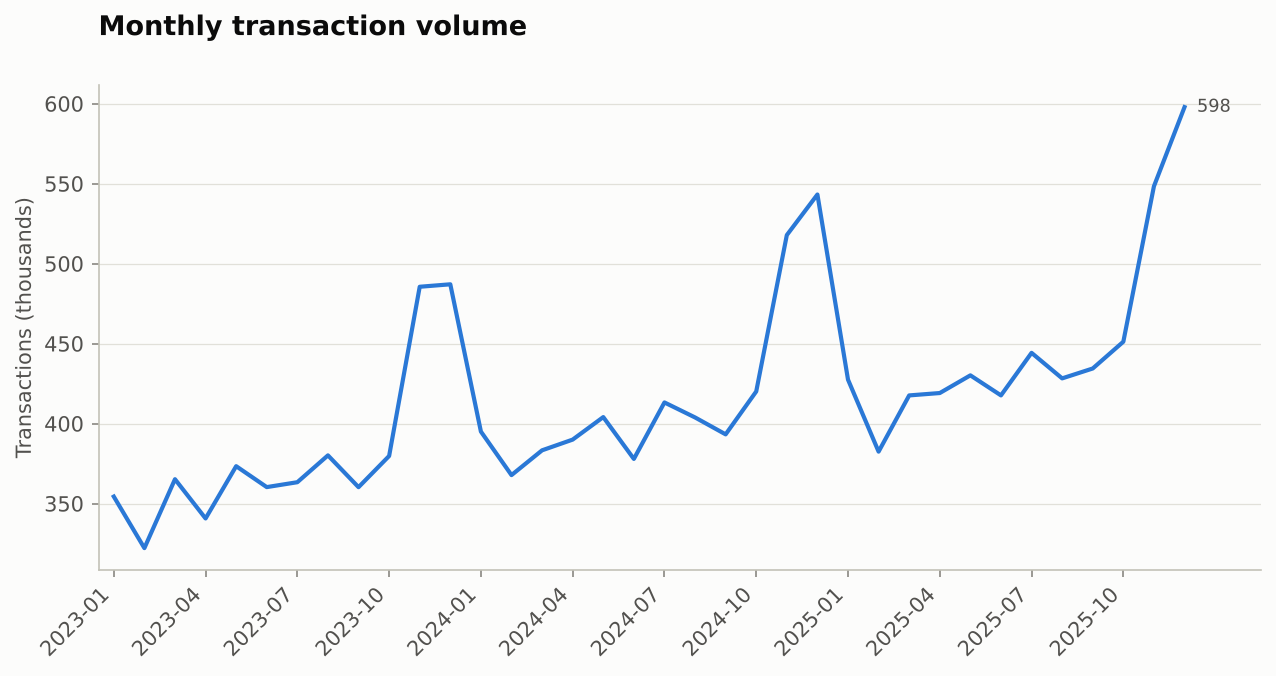

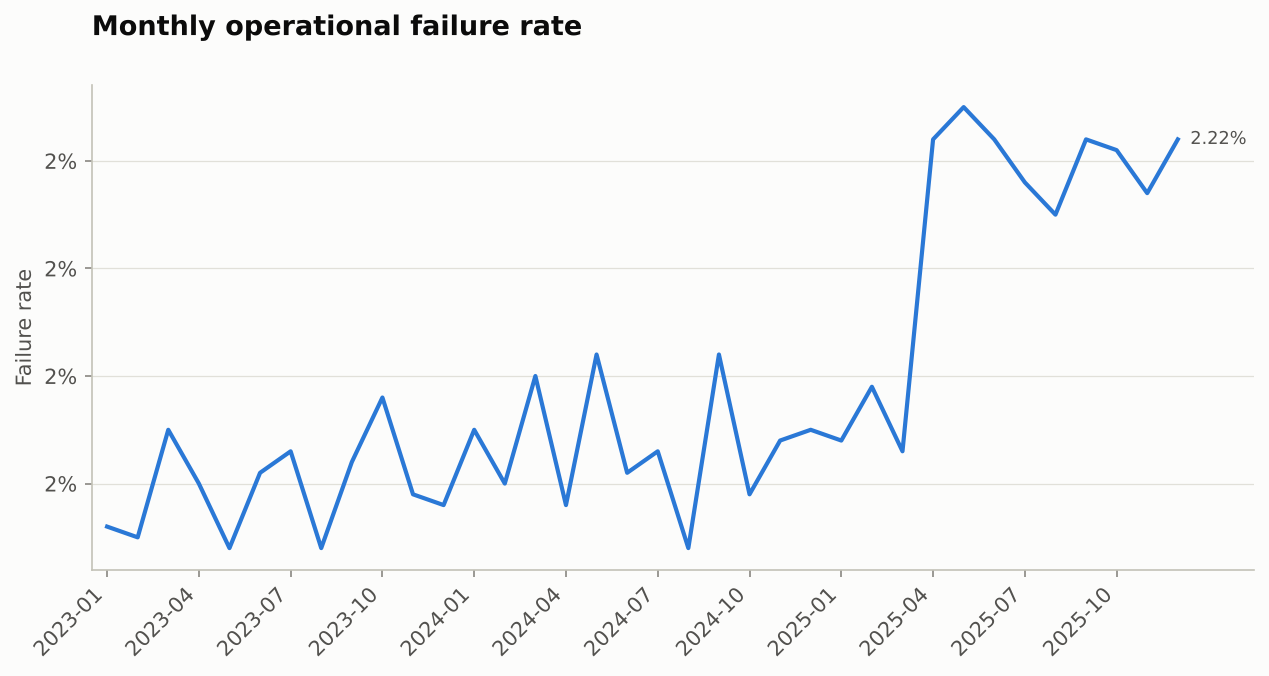

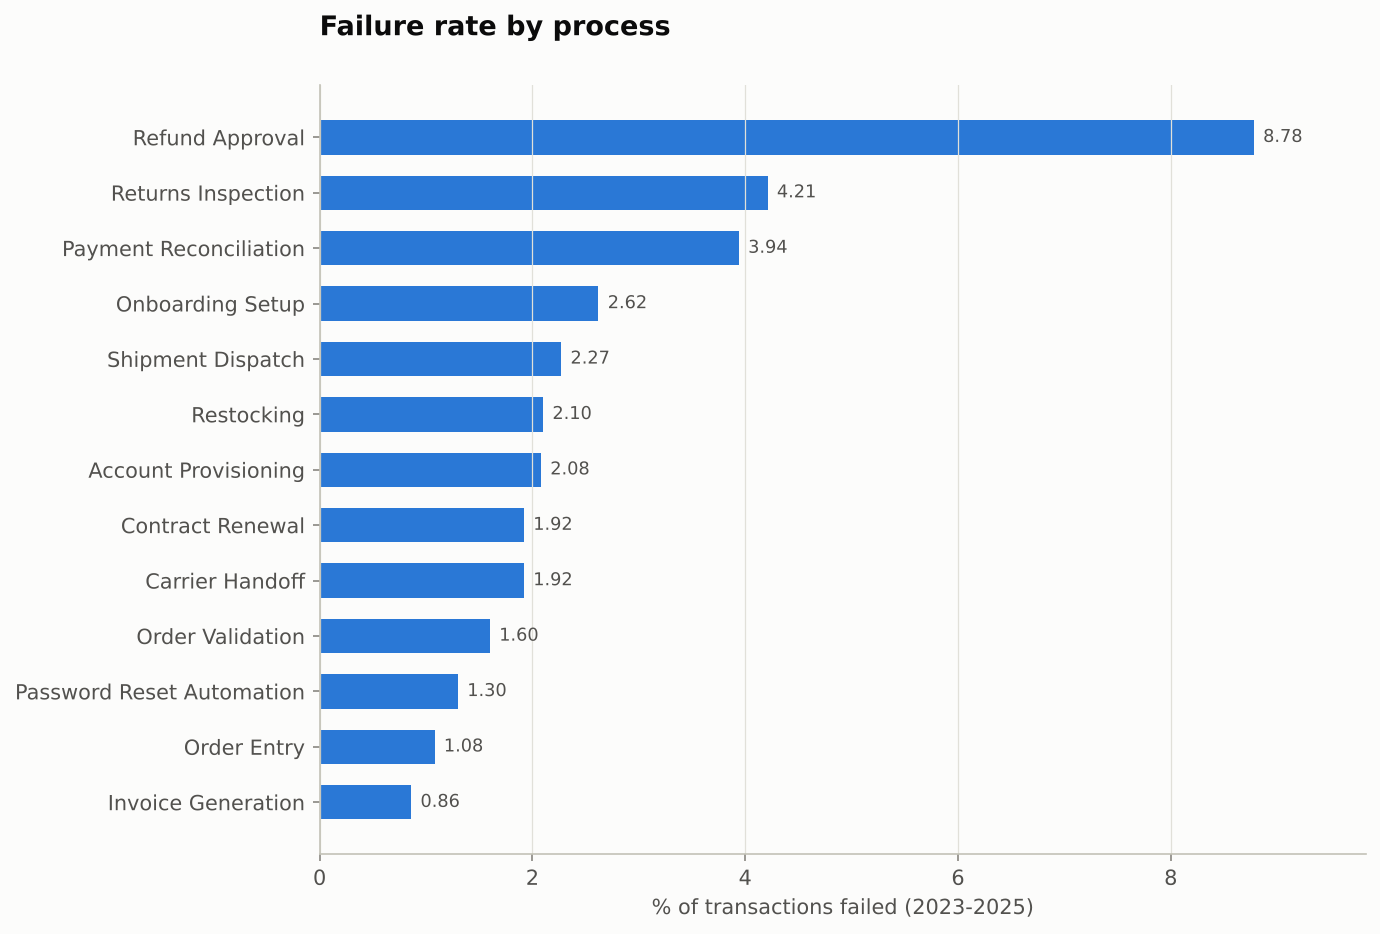

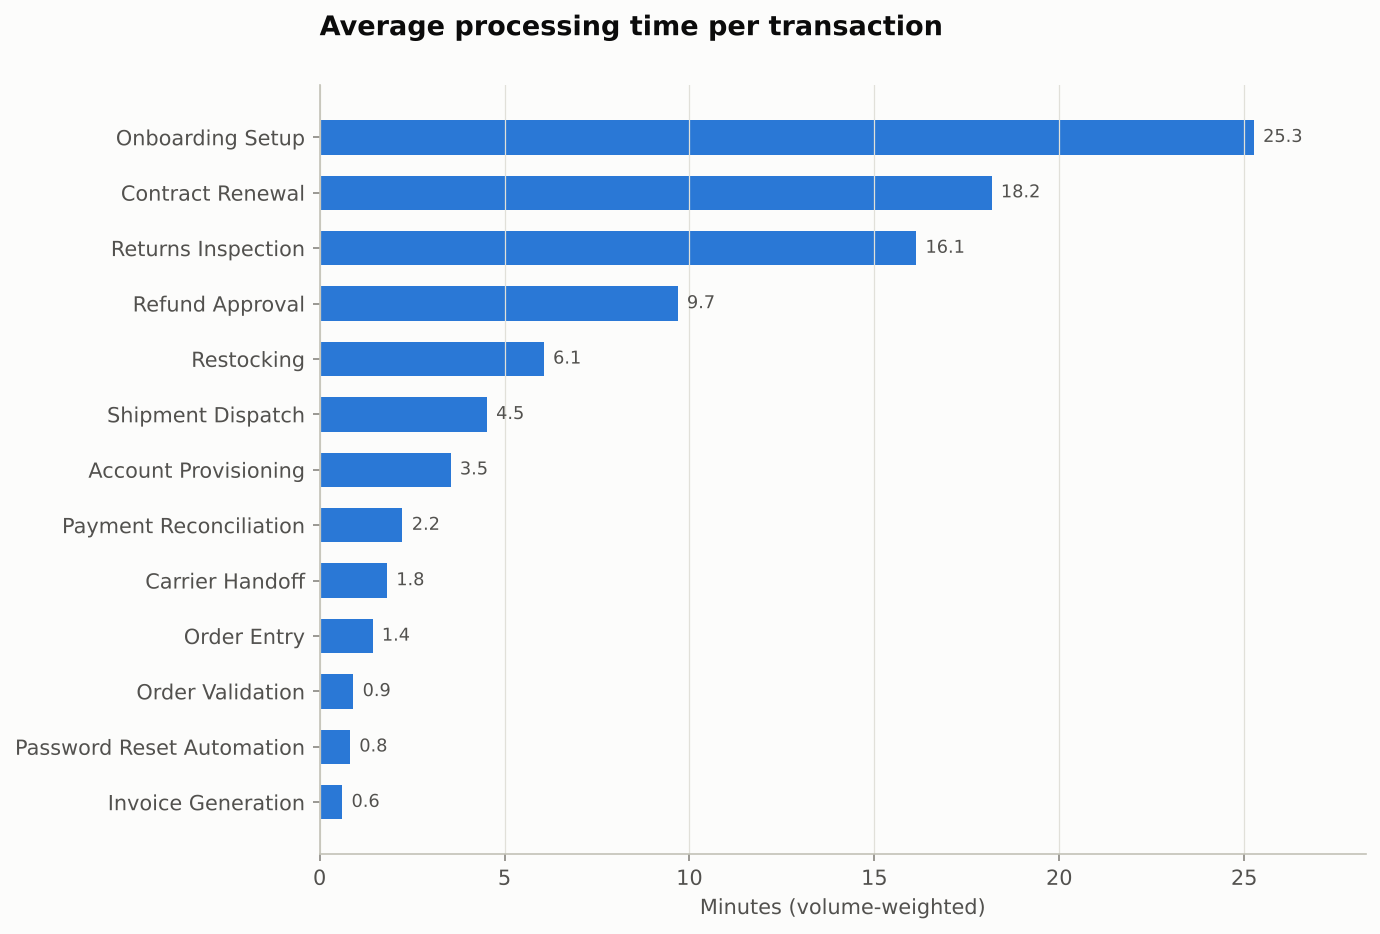

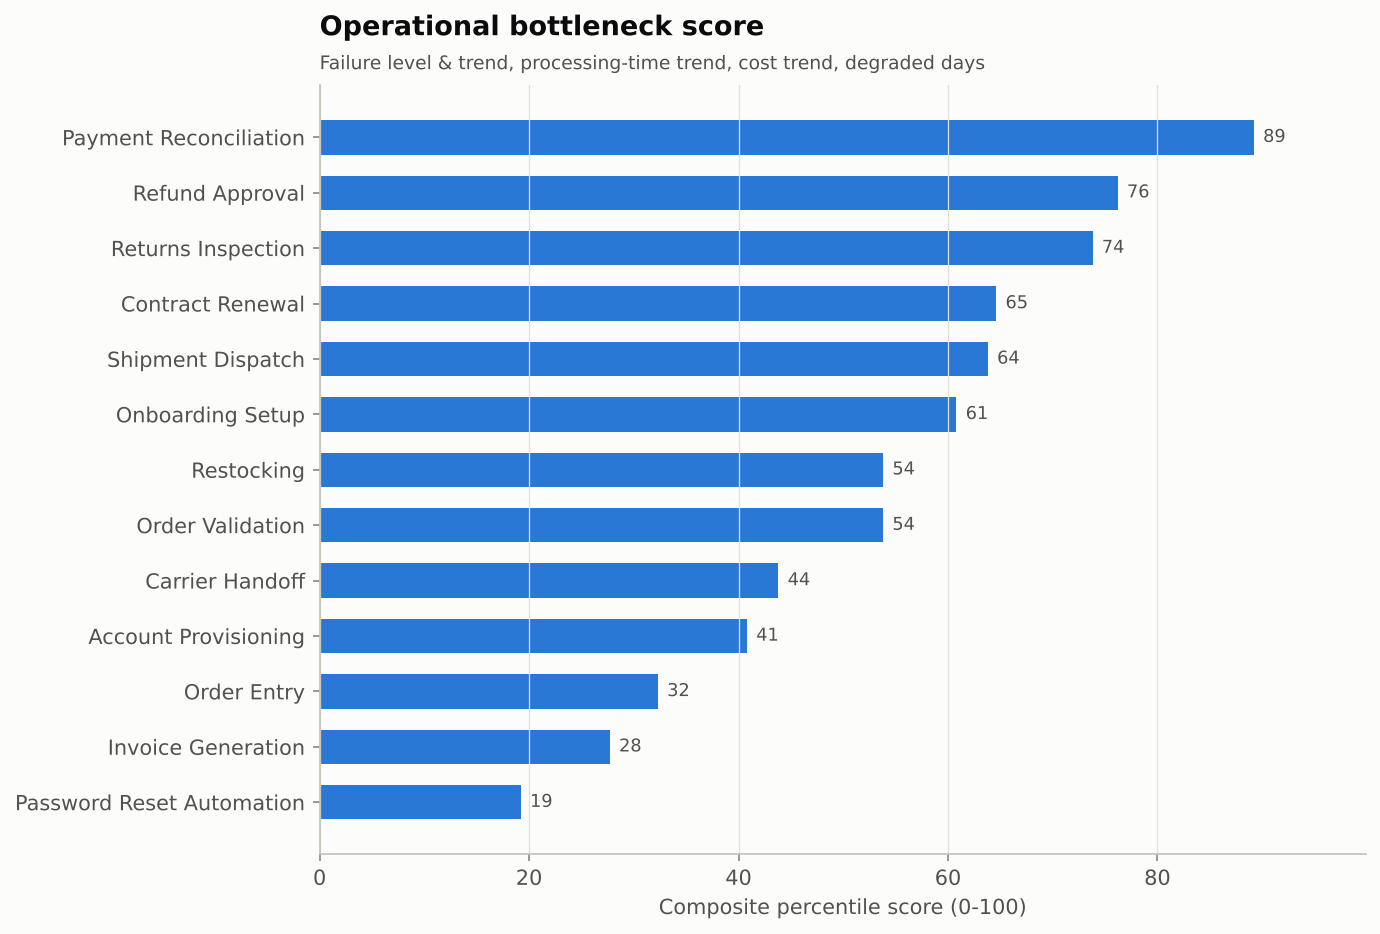

In [3]:
display(eda.bottleneck_table(o))
show("38_transactions_trend", "39_failure_rate_trend", "40_failure_rate_by_process", "43_processing_time_by_process", "47_bottleneck_score")

## Costs

,cost_category,direct,indirect,total
0,Personnel,"5,913,445.47","514,212.64","6,427,658.11"
1,Technology & Software,"1,238,014.56","309,503.68","1,547,518.24"
2,Outsourcing,"1,104,953.08","58,155.42","1,163,108.50"
3,Facilities,"264,510.57","617,191.23","881,701.80"
4,Telecommunications,"465,067.40","199,314.52","664,381.92"
5,Training & Development,"398,087.00","70,250.68","468,337.68"


,department_name,year,total_cost,budget,budget_utilisation_pct
0,Billing & Accounts,2023,"528,225.21","520,000.00",101.60
1,Billing & Accounts,2024,"547,452.73","520,000.00",105.30
2,Billing & Accounts,2025,"633,386.04","520,000.00",121.80
3,Customer Success,2023,"567,145.94","560,000.00",101.30
4,Customer Success,2024,"588,816.90","560,000.00",105.10
5,Customer Success,2025,"615,633.85","560,000.00",109.90
6,Logistics & Delivery,2023,"667,144.46","650,000.00",102.60
7,Logistics & Delivery,2024,"687,446.14","650,000.00",105.80
8,Logistics & Delivery,2025,"707,751.47","650,000.00",108.90
9,Order Management,2023,"490,973.17","480,000.00",102.30


,process_name,cost_2023,cost_2025,cost_change,cost_change_pct,volume_effect,unit_cost_effect,unit_cost_change_pct
0,Shipment Dispatch,"736,362.00","919,855.00","183,492.00",24.90,"133,832.00","49,660.00",5.70
1,Payment Reconciliation,"277,413.00","368,621.00","91,208.00",32.90,"51,745.00","39,463.00",12.00
2,Returns Inspection,"390,467.00","480,742.00","90,275.00",23.10,"71,818.00","18,457.00",4.00
3,Onboarding Setup,"334,143.00","408,648.00","74,505.00",22.30,"59,219.00","15,286.00",3.90
4,Carrier Handoff,"327,967.00","401,035.00","73,068.00",22.30,"57,948.00","15,120.00",3.90
5,Refund Approval,"278,533.00","335,408.00","56,875.00",20.40,"49,664.00","7,211.00",2.20
6,Order Entry,"227,610.00","275,240.00","47,630.00",20.90,"41,384.00","6,246.00",2.30
7,Order Validation,"222,542.00","268,402.00","45,861.00",20.60,"39,888.00","5,973.00",2.30
8,Account Provisioning,"190,922.00","229,973.00","39,050.00",20.50,"34,974.00","4,076.00",1.80
9,Contract Renewal,"183,731.00","220,654.00","36,923.00",20.10,"33,457.00","3,466.00",1.60


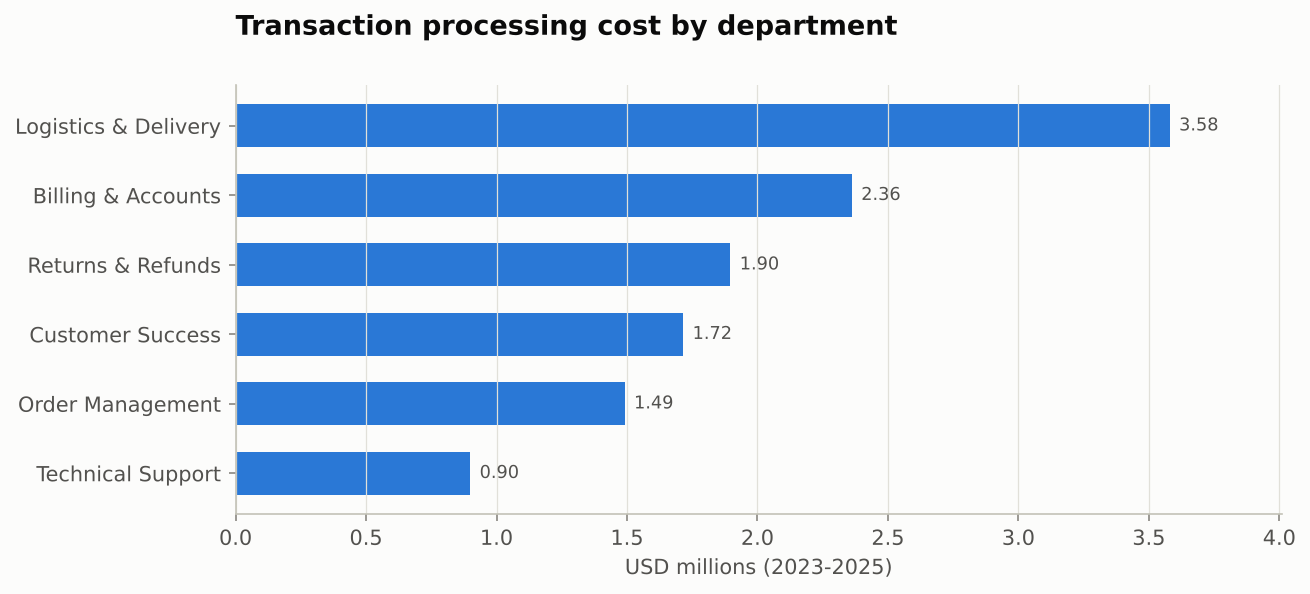

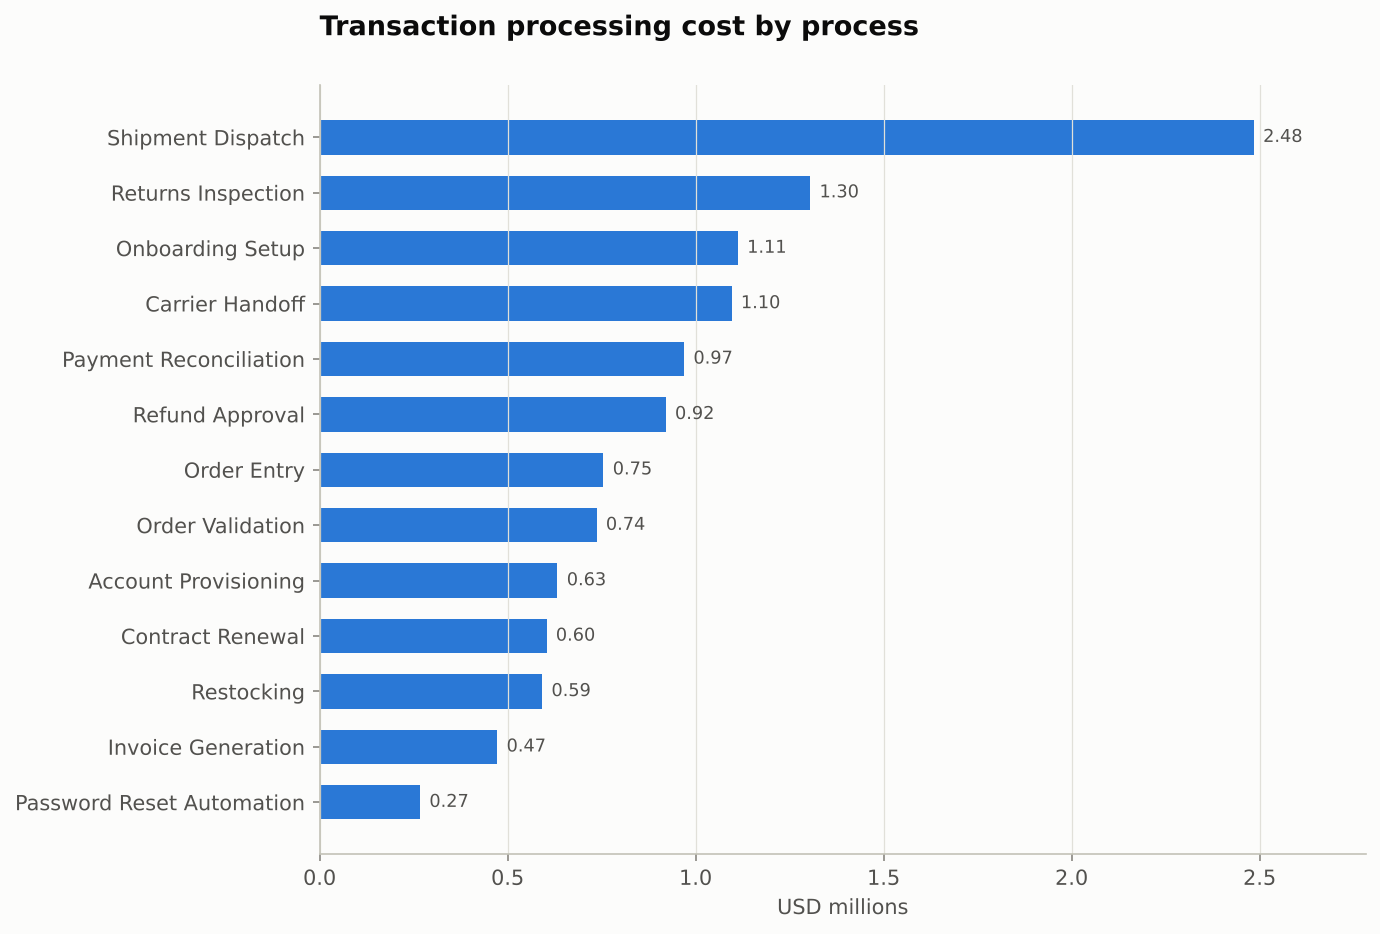

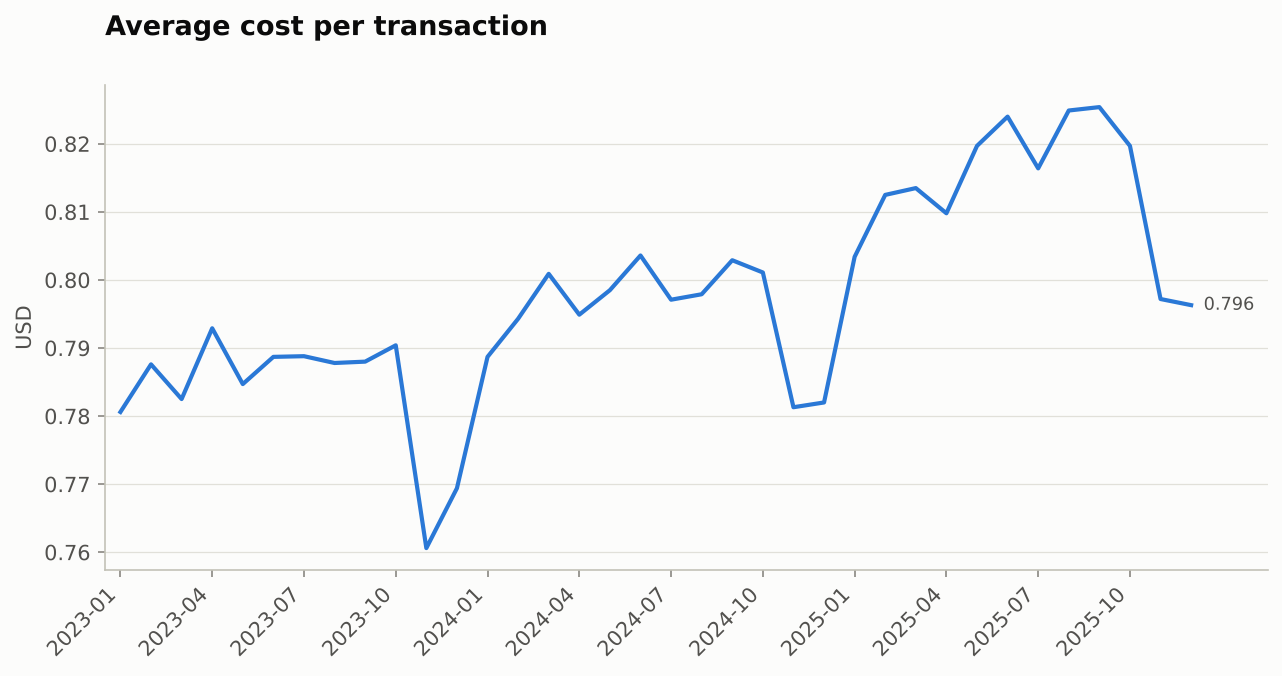

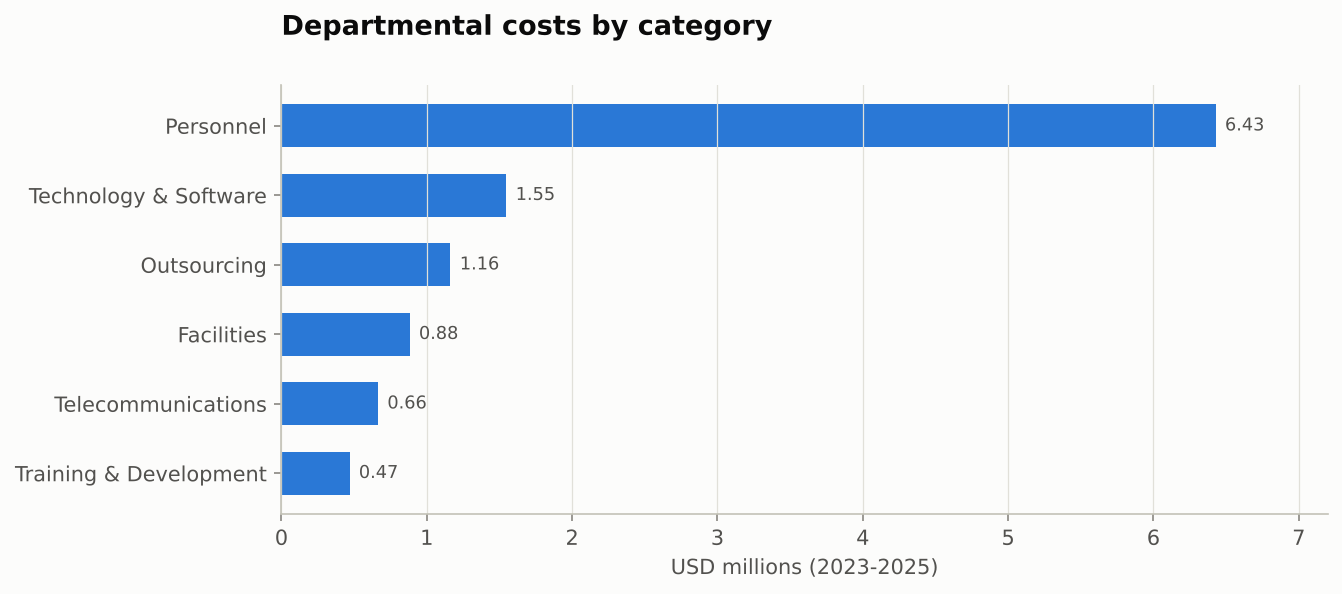

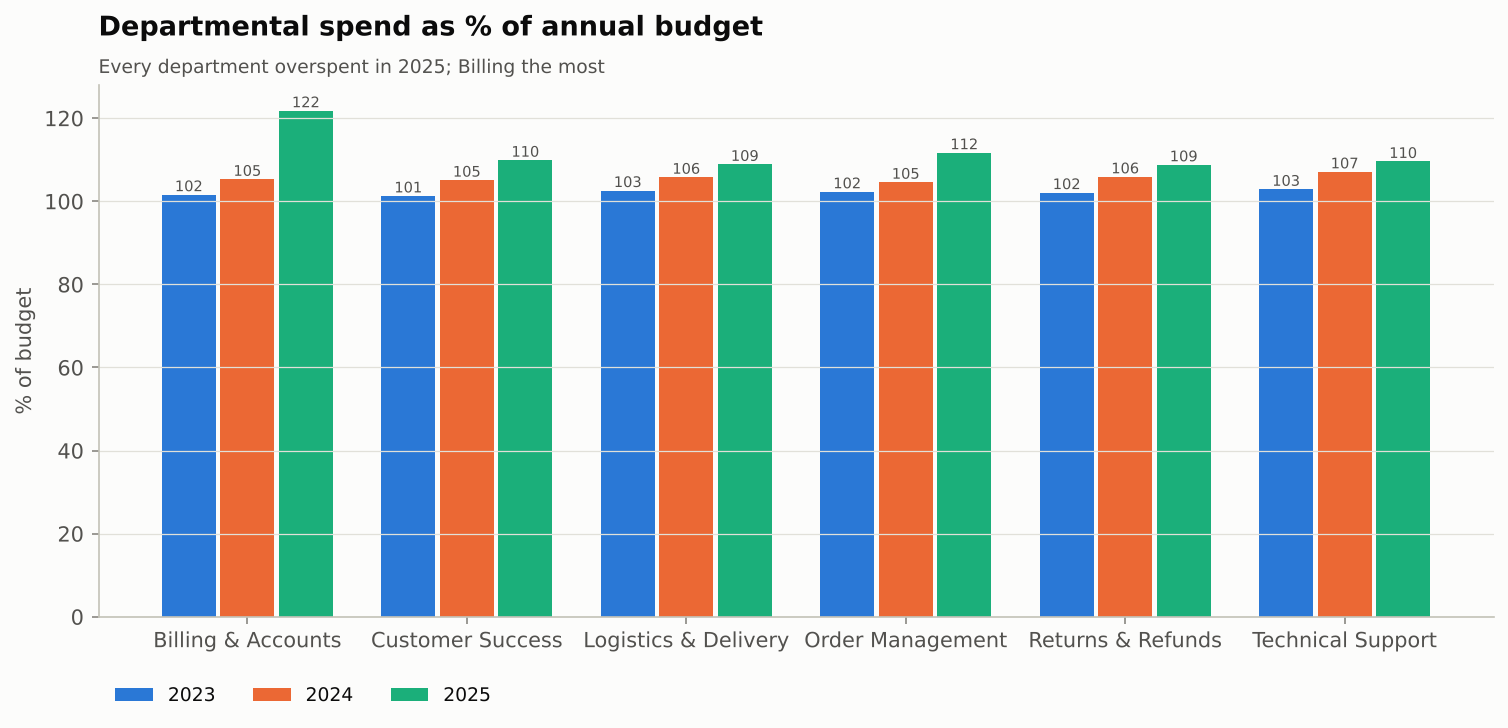

In [4]:
display(eda.costs_by(d["business_costs"], "cost_category"))
display(eda.costs_yearly_by_department(d["business_costs"], d["departments"]))
display(pd.read_csv(ROOT / "data/reports/rca_ops_cost_decomposition.csv"))
show("41_ops_cost_by_department", "42_ops_cost_by_process", "44_cost_per_transaction_trend", "45_business_costs_by_category", "46_budget_utilisation")

## Observations (seed 42)
* Overall operational success rate is ~98%, but **Refund Approval** fails ~9% of transactions and worsens every year.
* **Payment Reconciliation** failures nearly doubled after April 2025 — the same month Billing tickets jumped.
* **Shipment Dispatch** slows ~55% in Nov-Dec and is the largest cost line.
* ~80% of operational cost growth is explained by volume; the remainder is rising unit cost, led by Payment Reconciliation.
* All departments overspent their (flat) budgets in 2025; Billing the most (~122%).